<a href="https://colab.research.google.com/github/wilmar-barragan/Deep-Learning-SOLUCI-N-AL-PROBLEMA-COMPETENCIA-KAGGLE-/blob/main/SOLUCI%C3%93N_AL_PROBLEMA_%C2%BFCOMPETENCIA_KAGGLE%3F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ==============================================================================
# PROYECTO ML: CLASIFICACIÓN DE NIVELES DE OBESIDAD (KAGGLE / UCI)
# Modelo Seleccionado: Extra Trees Classifier (ETC) + Protocolo Split-First
# Basado en la metodología de AIDPCP (Shibly et al., 2026)
# ==============================================================================

# ------------------------------------------------------------------------------
# PASO 1: Instalación e Importación de Librerías
# ------------------------------------------------------------------------------
!pip install -q imbalanced-learn shap scikit-learn pandas numpy matplotlib seaborn

import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, log_loss
from imblearn.under_sampling import RandomUnderSampler
import shap

In [9]:
# PASO 2: Carga Automatizada del Dataset (UCI Machine Learning Repository / Kaggle)
# ------------------------------------------------------------------------------
url = "https://archive.ics.uci.edu/static/public/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip"
zip_path = "obesity.zip"

print("Descargando conjunto de datos oficial...")
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

# Corrección: El archivo oficial de UCI usa 'sinthetic' con 'i'
df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")
print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

Descargando conjunto de datos oficial...
Dataset cargado con éxito: 2111 filas y 17 columnas.



In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ankurbajaj9/obesity-levels")

print("Path to dataset files:", path)

100%|██████████| 115k/115k [00:00<00:00, 47.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/ankurbajaj9/obesity-levels/versions/1


In [10]:
# PASO 3: Protocolo SPLIT-FIRST (Garantía Antifuga de Datos / No Data Leakage)
# ------------------------------------------------------------------------------
# Nota: Esta celda requiere que la celda del Paso 2 se haya ejecutado correctamente primero.

# Separación de características y variable objetivo (NObeyesdad)
X = df.drop(columns=['NObeyesdad'])
y = df['NObeyesdad']

# Codificación de etiquetas multiclase
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# División Estricta 80% Entrenamiento y 20% Prueba (Estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"[Split-First] Registros en Entrenamiento (Train): {X_train.shape[0]}")
print(f"[Split-First] Registros en Prueba Independiente (Test): {X_test.shape[0]}")

[Split-First] Registros en Entrenamiento (Train): 1688
[Split-First] Registros en Prueba Independiente (Test): 423


In [12]:
# PASO 4: Preprocesamiento Adaptativo AIDPCP
# ------------------------------------------------------------------------------
num_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
cat_cols = ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Ajuste (fit) EXCLUSIVAMENTE sobre X_train y transformación sobre X_train y X_test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)  # Transformación congelada para test

# Balanceo de clases (Random Undersampling) aplicado SOLO en Train
rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train_prep, y_train)

print(f"\nForma de X_train procesado y balanceado: {X_train_res.shape}")


Forma de X_train procesado y balanceado: (1526, 31)


In [14]:
# PASO 5: Entrenamiento del Modelo Base (Extra Trees Classifier - ETC)
# ------------------------------------------------------------------------------

etc_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

etc_model.fit(X_train_res, y_train_res)
print("Modelo Extra Trees Classifier (ETC) entrenado exitosamente.")
# ------------------------------------------------------------------------------

Modelo Extra Trees Classifier (ETC) entrenado exitosamente.


=== EVALUACIÓN DEL MODELO ETC ===
Accuracy en Test: 0.9173
Log Loss en Test: 0.3317

Reporte de Clasificación:
                     precision    recall  f1-score   support

Insufficient_Weight       0.95      0.96      0.95        54
      Normal_Weight       0.72      0.86      0.79        58
     Obesity_Type_I       0.93      0.93      0.93        70
    Obesity_Type_II       1.00      0.97      0.98        60
   Obesity_Type_III       0.98      0.98      0.98        65
 Overweight_Level_I       0.89      0.84      0.87        58
Overweight_Level_II       0.98      0.86      0.92        58

           accuracy                           0.92       423
          macro avg       0.92      0.92      0.92       423
       weighted avg       0.92      0.92      0.92       423



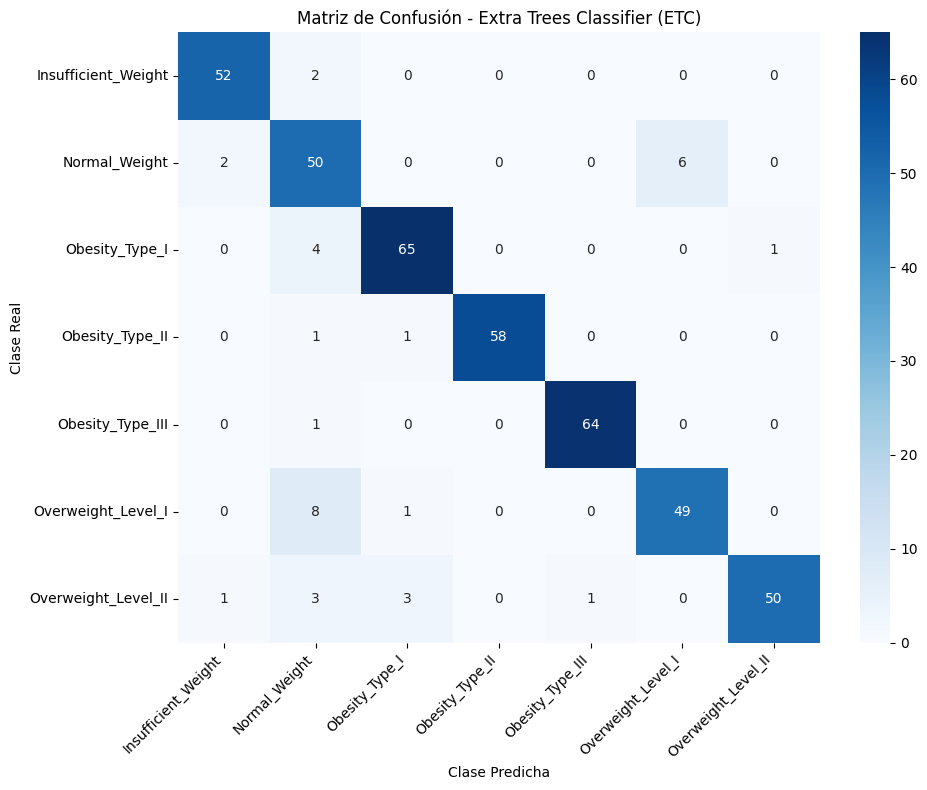

In [15]:
# PASO 6: Evaluación del Modelo sobre el Conjunto de Test Independiente
# ------------------------------------------------------------------------------

# 1. Realizar predicciones en el conjunto de test congelado
y_pred = etc_model.predict(X_test_prep)
y_pred_proba = etc_model.predict_proba(X_test_prep)

# 2. Calcular métricas globales
accuracy = accuracy_score(y_test, y_pred)
loss = log_loss(y_test, y_pred_proba)

print(f"=== EVALUACIÓN DEL MODELO ETC ===")
print(f"Accuracy en Test: {accuracy:.4f}")
print(f"Log Loss en Test: {loss:.4f}\n")

# 3. Reporte de Clasificación Detallado por Clase
print("Reporte de Clasificación:")
target_names = le.classes_
print(classification_report(y_test, y_pred, target_names=target_names))

# 4. Visualización de la Matriz de Confusión
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Matriz de Confusión - Extra Trees Classifier (ETC)')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Calculando y graficando los valores SHAP globales...


<Figure size 1200x800 with 0 Axes>

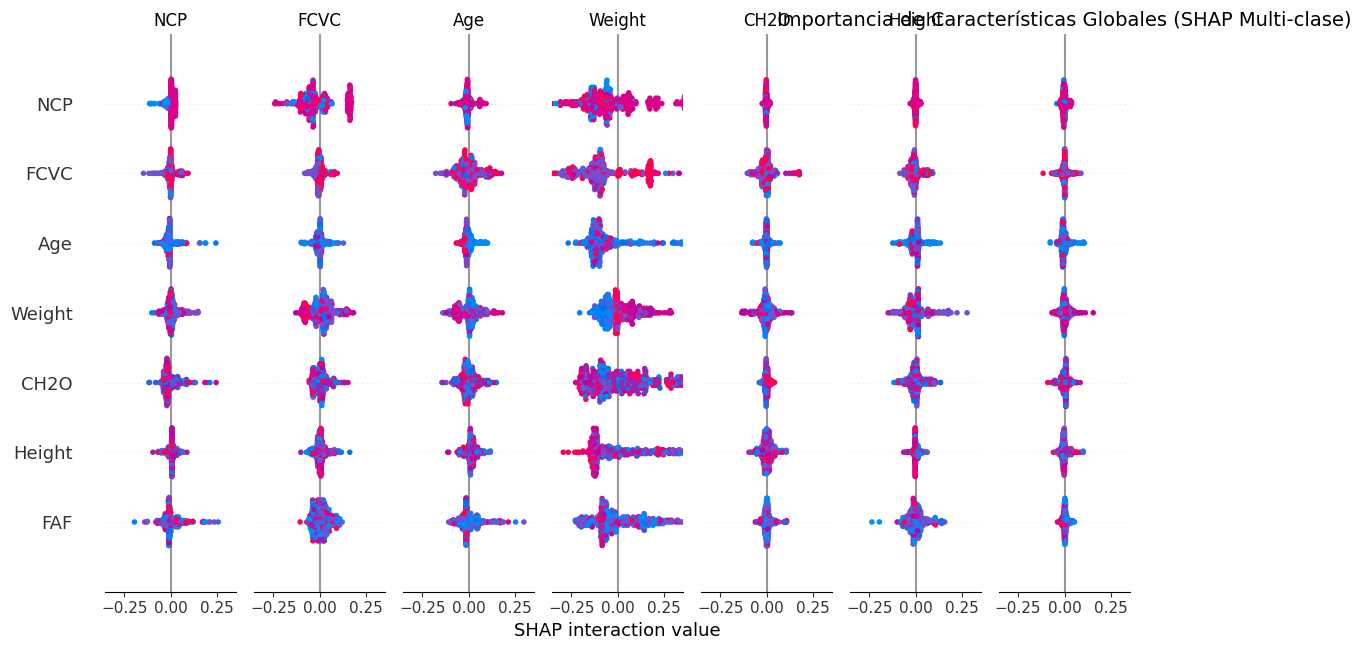

In [16]:
# PASO 7: Explicabilidad Global y Local mediante SHAP
# ------------------------------------------------------------------------------

# 1. Recuperar los nombres de las características transformadas por el ColumnTransformer
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + encoded_cat_cols

# 2. Inicializar el explicador SHAP específico para árboles (TreeExplainer)
explainer = shap.TreeExplainer(etc_model)

# 3. Calcular los valores SHAP para el conjunto de test preprocesado
# Nota: Usamos una fracción representativa del test para optimizar el tiempo de cálculo si es necesario
shap_values = explainer.shap_values(X_test_prep)

# 4. Visualización de la Importancia Global de las Características
print("Calculando y graficando los valores SHAP globales...")
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_prep, feature_names=feature_names, show=False)
plt.title("Importancia de Características Globales (SHAP Multi-clase)", fontsize=14)
plt.tight_layout()
plt.show()


Generando gráfico de explicabilidad SHAP...


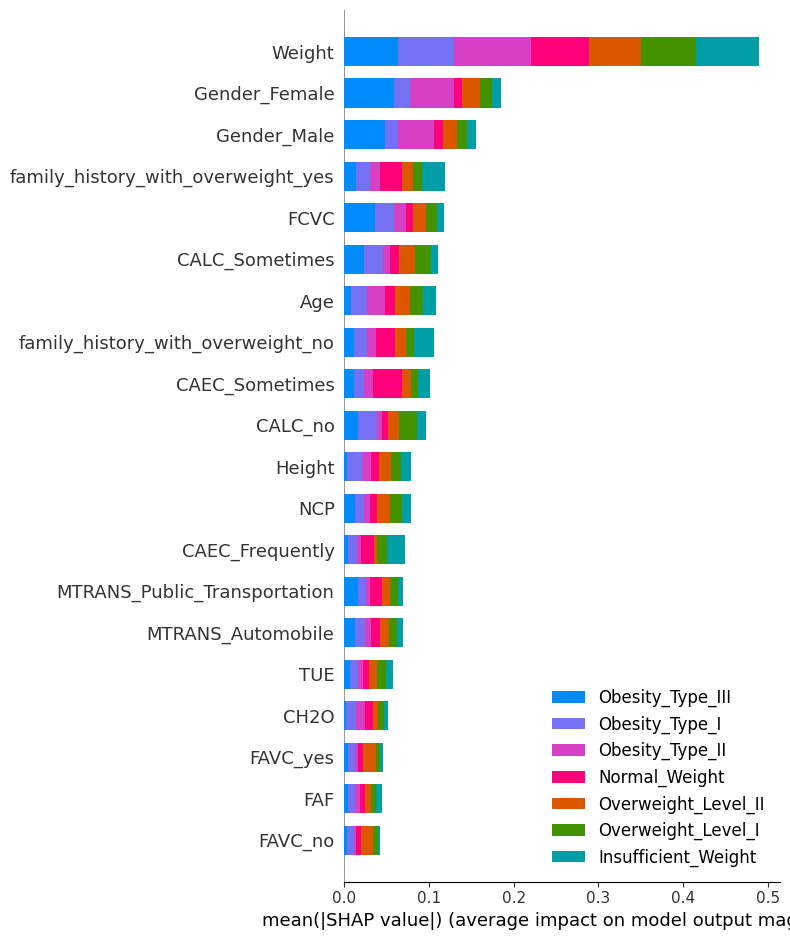

In [18]:
# PASO 7: Auditoría de Explicabilidad (XAI) con SHAP
# ------------------------------------------------------------------------------
print("\nGenerando gráfico de explicabilidad SHAP...")

feature_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
explainer = shap.TreeExplainer(etc_model)
shap_values = explainer.shap_values(X_test_prep)

# Gráfico de Importancia Global de Variables
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_prep, feature_names=feature_names, class_names=le.classes_, plot_type="bar")